# Retail Store Performance Analysis and Sales Prediction
### AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026 | BharatCares

**Author:** Maanveer Singh
**Project:** Retail Store Performance Analysis and Sales Prediction (Data Analytics with AI)

---

## 1. Problem Statement
A supermarket chain operates hundreds of stores of different sizes and traffic levels, but its sales are very uneven. The business wants to know:

1. How do store size, stock range and customer traffic relate to store sales?
2. Which stores are the most and least efficient in turning floor space into revenue?
3. Can stores be grouped into meaningful segments for planning?
4. Can machine learning predict a store's sales from its physical and traffic characteristics?

## 2. Objectives
- Clean and validate the dataset.
- Explore distributions, outliers and relationships between variables.
- Engineer business KPIs (sales per sq yd, sales per customer, and more).
- Test relationships statistically instead of judging charts by eye.
- Segment stores with K-Means clustering.
- Build and compare regression models to predict `Store_Sales`, and report honestly how well they work.

## 3. Dataset
| Item | Detail |
|---|---|
| File | `Use_Stores.csv` |
| Rows | 896 stores (one row per store) |
| Columns | Store ID, Store_Area, Items_Available, Daily_Customer_Count, Store_Sales |
| Source | Kaggle: *Supermarket Store Branches Sales Analysis* by surajjha101 (link in README.md) |
| Units | `Store_Area` in square yards (sq yd), `Store_Sales` in US dollars (USD) |

## 4. Import Libraries

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.model_selection import KFold, cross_val_score, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

RANDOM_STATE = 42
os.makedirs("charts", exist_ok=True)   # charts are also saved as PNG files

def save_chart(name):
    plt.tight_layout()
    plt.savefig(f"charts/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 5. Load the Dataset
The raw file has two small quirks that would cause bugs later: a hidden BOM character at the start of the file and a trailing space in the first column name (`'Store ID '`). Both are fixed while loading.

In [2]:
df = pd.read_csv("Use_Stores.csv", encoding="utf-8-sig")   # utf-8-sig removes the hidden BOM
print("Raw column names:", df.columns.tolist())

df.columns = df.columns.str.strip()                         # remove stray spaces
df = df.rename(columns={"Store ID": "Store_ID"})
print("Clean column names:", df.columns.tolist())
df.head(10)

Raw column names: ['Store ID ', 'Store_Area', 'Items_Available', 'Daily_Customer_Count', 'Store_Sales']
Clean column names: ['Store_ID', 'Store_Area', 'Items_Available', 'Daily_Customer_Count', 'Store_Sales']


,Store_ID,Store_Area,Items_Available,Daily_Customer_Count,Store_Sales
0,1,1659,1961,530,66490
1,2,1461,1752,210,39820
2,3,1340,1609,720,54010
3,4,1451,1748,620,53730
4,5,1770,2111,450,46620
5,6,1442,1733,760,45260
6,7,1542,1858,1030,72240
7,8,1261,1507,1020,37720
8,9,1090,1321,680,46310
9,10,1030,1235,1130,44150


## 6. Data Quality Checks

In [3]:
print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (896, 5)

<class 'pandas.DataFrame'>
RangeIndex: 896 entries, 0 to 895
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Store_ID              896 non-null    int64
 1   Store_Area            896 non-null    int64
 2   Items_Available       896 non-null    int64
 3   Daily_Customer_Count  896 non-null    int64
 4   Store_Sales           896 non-null    int64
dtypes: int64(5)
memory usage: 35.1 KB


In [4]:
quality = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Unique values": df.nunique(),
    "Min": df.min(),
    "Max": df.max(),
})
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Store IDs:", df["Store_ID"].duplicated().sum())
print("Any zero or negative values:", bool((df <= 0).any().any()))
quality

Duplicate rows: 0
Duplicate Store IDs: 0
Any zero or negative values: False


,Missing values,Unique values,Min,Max
Store_ID,0,896,1,896
Store_Area,0,583,775,2229
Items_Available,0,616,932,2667
Daily_Customer_Count,0,130,10,1560
Store_Sales,0,816,14920,116320


**Result:** there are no missing values, no duplicate rows and no zero or negative values, so no rows had to be dropped or imputed. The data types are all numeric and correct.

## 7. Feature Engineering (Business KPIs)
Raw columns alone cannot answer efficiency questions, so five KPIs are created:

| KPI | Formula | Business meaning |
|---|---|---|
| `Sales_per_SqYd` | Store_Sales / Store_Area | Revenue earned from each unit of floor space |
| `Sales_per_Customer` | Store_Sales / Daily_Customer_Count | Average value of a customer visit |
| `Customers_per_100SqYd` | Daily_Customer_Count / Store_Area x 100 | Footfall density |
| `Items_per_SqYd` | Items_Available / Store_Area | Stock range density |
| `Store_Size` | Quartiles of Store_Area | Small / Medium / Large / Extra Large |

In [5]:
df["Sales_per_SqYd"] = df["Store_Sales"] / df["Store_Area"]
df["Sales_per_Customer"] = df["Store_Sales"] / df["Daily_Customer_Count"]
df["Customers_per_100SqYd"] = df["Daily_Customer_Count"] / df["Store_Area"] * 100
df["Items_per_SqYd"] = df["Items_Available"] / df["Store_Area"]
df["Store_Size"] = pd.qcut(df["Store_Area"], 4, labels=["Small", "Medium", "Large", "Extra Large"])

df[["Store_ID", "Store_Area", "Daily_Customer_Count", "Store_Sales",
    "Sales_per_SqYd", "Sales_per_Customer", "Customers_per_100SqYd", "Items_per_SqYd", "Store_Size"]].head()

,Store_ID,Store_Area,Daily_Customer_Count,Store_Sales,Sales_per_SqYd,Sales_per_Customer,Customers_per_100SqYd,Items_per_SqYd,Store_Size
0,1,1659,530,66490,40.08,125.45,31.95,1.18,Extra Large
1,2,1461,210,39820,27.26,189.62,14.37,1.20,Medium
2,3,1340,720,54010,40.31,75.01,53.73,1.20,Medium
3,4,1451,620,53730,37.03,86.66,42.73,1.20,Medium
4,5,1770,450,46620,26.34,103.60,25.42,1.19,Extra Large


## 8. Descriptive Statistics

In [6]:
core = ["Store_Area", "Items_Available", "Daily_Customer_Count", "Store_Sales"]
summary = df[core].describe().T
summary["skewness"] = df[core].skew()
summary

,count,mean,std,min,25%,50%,75%,max,skewness
Store_Area,896.00,"1,485.41",250.24,775.00,"1,316.75","1,477.00","1,653.50","2,229.00",0.03
Items_Available,896.00,"1,782.04",299.87,932.00,"1,575.50","1,773.50","1,982.75","2,667.00",0.03
Daily_Customer_Count,896.00,786.35,265.39,10.00,600.00,780.00,970.00,"1,560.00",0.07
Store_Sales,896.00,"59,351.31","17,190.74","14,920.00","46,530.00","58,605.00","71,872.50","116,320.00",0.15


In [7]:
kpis = ["Sales_per_SqYd", "Sales_per_Customer", "Customers_per_100SqYd", "Items_per_SqYd"]
df[kpis].describe().T

,count,mean,std,min,25%,50%,75%,max
Sales_per_SqYd,896.00,40.99,13.70,11.08,31.07,39.78,48.73,96.31
Sales_per_Customer,896.00,94.04,162.82,15.07,55.88,75.41,102.85,"4,548.00"
Customers_per_100SqYd,896.00,54.71,21.67,0.79,39.39,53.60,67.60,169.75
Items_per_SqYd,896.00,1.20,0.01,1.17,1.19,1.20,1.21,1.23


## 9. Distribution of Each Variable

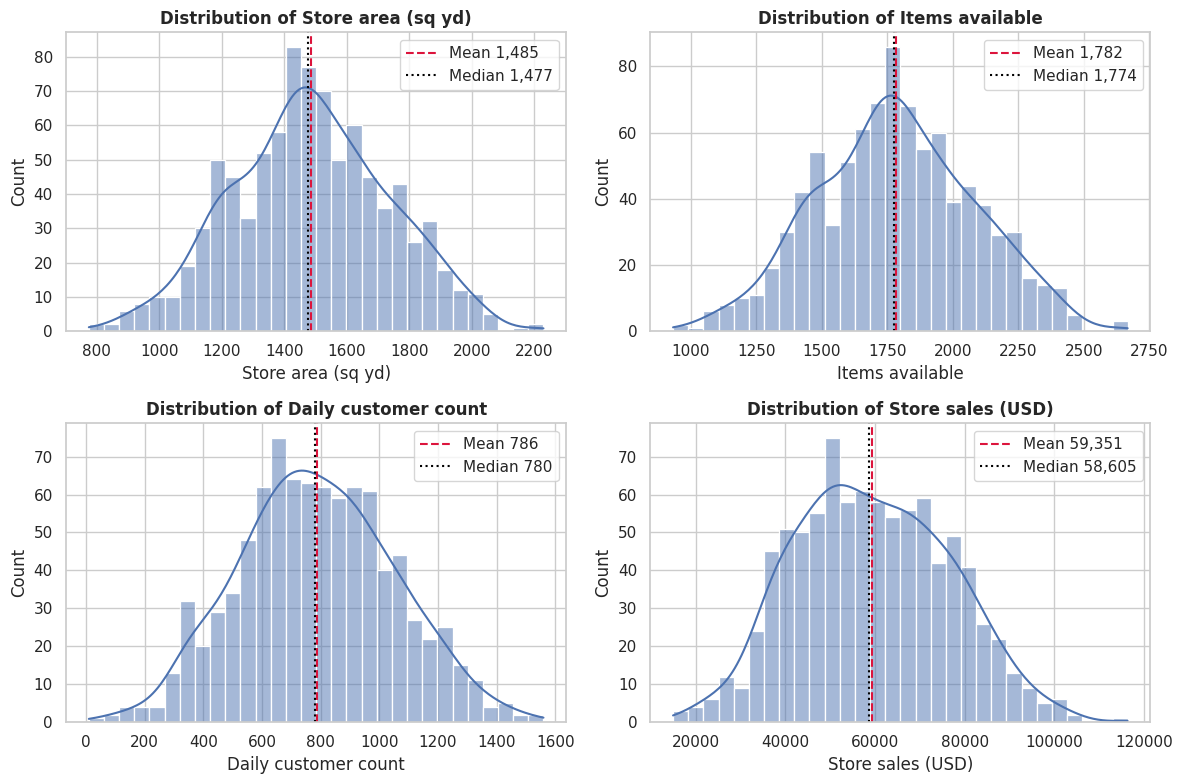

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
labels = {"Store_Area": "Store area (sq yd)", "Items_Available": "Items available",
          "Daily_Customer_Count": "Daily customer count", "Store_Sales": "Store sales (USD)"}
for ax, col in zip(axes.ravel(), core):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.axvline(df[col].mean(), color="crimson", linestyle="--", label=f"Mean {df[col].mean():,.0f}")
    ax.axvline(df[col].median(), color="black", linestyle=":", label=f"Median {df[col].median():,.0f}")
    ax.set_title(f"Distribution of {labels[col]}")
    ax.set_xlabel(labels[col])
    ax.legend()
save_chart("01_distributions")

All four variables are roughly bell-shaped with only mild skew, so mean and median are close. Store sales are centred near USD 59,000 and the middle half of stores fall between about USD 46,500 and USD 71,900.

## 10. Outlier Detection (IQR Method)
A value is flagged as an outlier if it lies more than 1.5 x IQR below Q1 or above Q3.

In [9]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (series < low) | (series > high), low, high

rows = []
for col in core:
    mask, low, high = iqr_outliers(df[col])
    rows.append({"Variable": col, "Lower fence": low, "Upper fence": high,
                 "Outliers": int(mask.sum()), "% of stores": mask.mean() * 100})
outlier_table = pd.DataFrame(rows).set_index("Variable")
outlier_table

,Lower fence,Upper fence,Outliers,% of stores
Variable,,,,
Store_Area,811.62,"2,158.62",5,0.56
Items_Available,964.62,"2,593.62",5,0.56
Daily_Customer_Count,45.00,"1,525.00",3,0.33
Store_Sales,"8,516.25","109,886.25",1,0.11


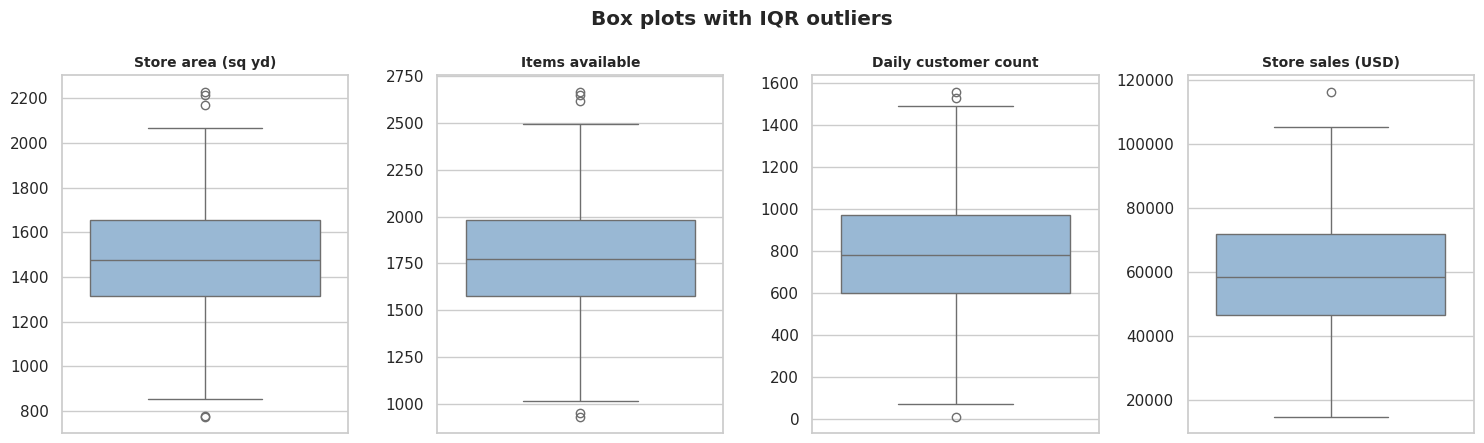

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
for ax, col in zip(axes, core):
    sns.boxplot(y=df[col], ax=ax, color="#8fb8de")
    ax.set_title(labels[col], fontsize=10)
    ax.set_ylabel("")
fig.suptitle("Box plots with IQR outliers", fontweight="bold")
save_chart("02_boxplots")

In [11]:
# Which stores are unusual? Look at the extreme customer counts.
df.nsmallest(5, "Daily_Customer_Count")[["Store_ID", "Store_Area", "Daily_Customer_Count", "Store_Sales", "Sales_per_Customer"]]

,Store_ID,Store_Area,Daily_Customer_Count,Store_Sales,Sales_per_Customer
39,40,1270,10,45480,"4,548.00"
151,152,1662,70,63730,910.43
876,877,1259,100,88270,882.70
230,231,1347,120,72350,602.92
146,147,1442,130,58920,453.23


**Decision:** fewer than 1% of stores are outliers in any variable, and they look like genuine large/small stores rather than data entry errors, so they are **kept**. One store (ID 40) reports only 10 daily customers but USD 45,480 in sales. That is about USD 4,548 per customer, over 40 times the typical value, so it is most likely a data-recording error in the customer count. It is flagged here and kept in the analysis, because removing a single row does not change any conclusion (this is checked again in the modelling section).

## 11. Correlation Analysis

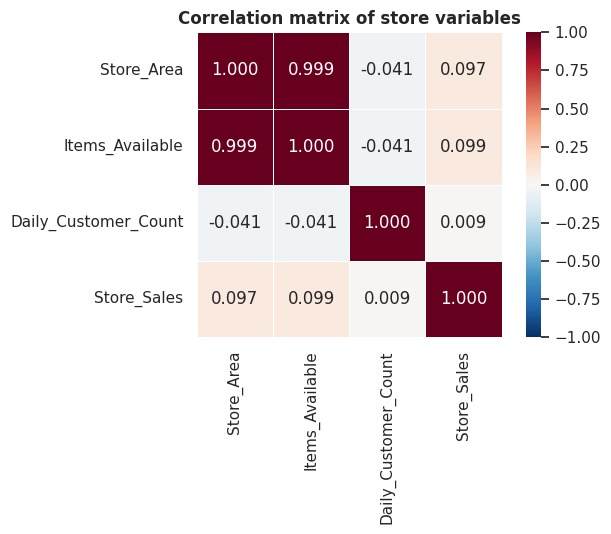

,Store_Area,Items_Available,Daily_Customer_Count,Store_Sales
Store_Area,1.00,1.00,-0.04,0.10
Items_Available,1.00,1.00,-0.04,0.10
Daily_Customer_Count,-0.04,-0.04,1.00,0.01
Store_Sales,0.10,0.10,0.01,1.00


In [12]:
corr = df[core].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation matrix of store variables")
save_chart("03_correlation_heatmap")
corr

Two things stand out:

1. **`Store_Area` and `Items_Available` are almost perfectly correlated (r = 0.999).** Stock range is simply about 1.2 items per sq yd everywhere, so the two columns carry the same information. Using both in a model would add nothing and cause multicollinearity.
2. **`Store_Sales` has almost no linear relationship with any other column** (r is about 0.10 with area and 0.01 with customers). Bigger stores and busier stores do not sell much more.

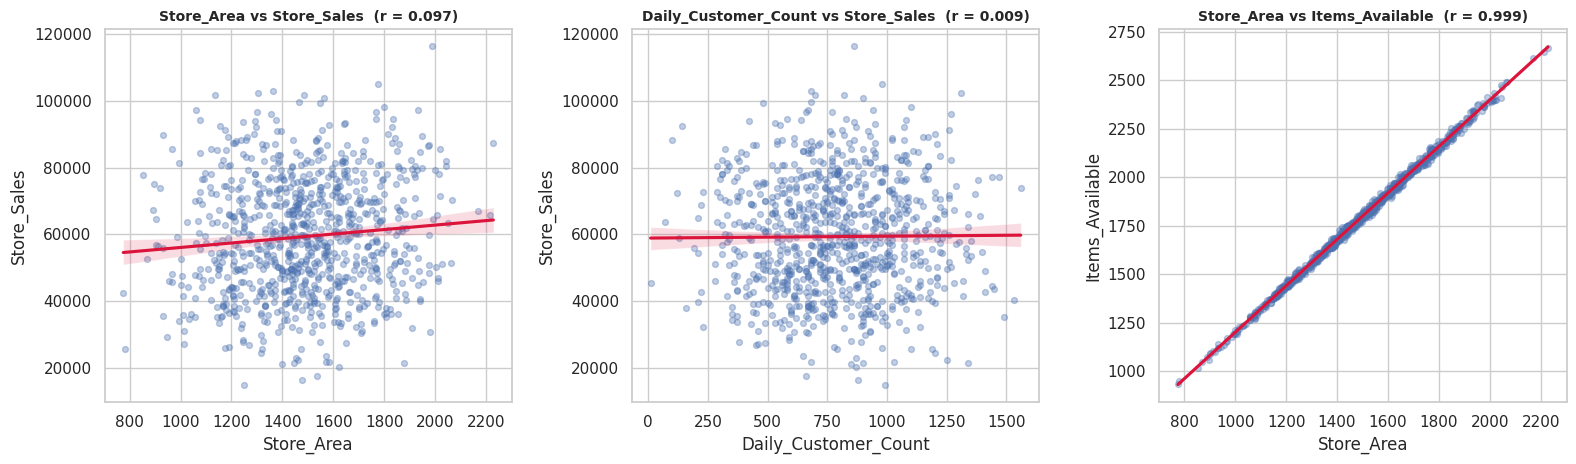

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
pairs = [("Store_Area", "Store_Sales"), ("Daily_Customer_Count", "Store_Sales"), ("Store_Area", "Items_Available")]
for ax, (x, y) in zip(axes, pairs):
    sns.regplot(data=df, x=x, y=y, ax=ax, scatter_kws={"alpha": 0.35, "s": 18},
                line_kws={"color": "crimson"})
    r = df[x].corr(df[y])
    ax.set_title(f"{x} vs {y}  (r = {r:.3f})", fontsize=10)
save_chart("04_scatter_relationships")

## 12. Statistical Hypothesis Tests
Charts can mislead, so the relationships are tested formally (significance level 0.05).

- **H0:** no relationship between the variable and store sales. **H1:** a relationship exists.
- Pearson correlation (linear) and Spearman correlation (rank based, robust to outliers) are both used.
- One-way ANOVA and the Kruskal-Wallis test check whether average sales differ across the four store-size groups.

In [14]:
results = []
for col in ["Store_Area", "Items_Available", "Daily_Customer_Count"]:
    pr, pp = stats.pearsonr(df[col], df["Store_Sales"])
    sr, sp = stats.spearmanr(df[col], df["Store_Sales"])
    results.append({"Variable vs Store_Sales": col, "Pearson r": pr, "Pearson p": pp,
                    "Spearman rho": sr, "Spearman p": sp,
                    "R-squared (%)": pr ** 2 * 100,
                    "Significant (p<0.05)": "Yes" if pp < 0.05 else "No"})
pd.DataFrame(results).set_index("Variable vs Store_Sales").round(4)

,Pearson r,Pearson p,Spearman rho,Spearman p,R-squared (%),Significant (p<0.05)
Variable vs Store_Sales,,,,,,
Store_Area,0.10,0.00,0.09,0.01,0.95,Yes
Items_Available,0.10,0.00,0.09,0.01,0.98,Yes
Daily_Customer_Count,0.01,0.80,0.02,0.56,0.01,No


In [15]:
groups = [g["Store_Sales"].values for _, g in df.groupby("Store_Size", observed=True)]
f_stat, f_p = stats.f_oneway(*groups)
h_stat, h_p = stats.kruskal(*groups)
print(f"ANOVA          : F = {f_stat:.3f}, p = {f_p:.4f}")
print(f"Kruskal-Wallis : H = {h_stat:.3f}, p = {h_p:.4f}")
print("Conclusion     :", "average sales differ between size groups" if min(f_p, h_p) < 0.05
      else "no significant difference in average sales between size groups")

ANOVA          : F = 1.918, p = 0.1251
Kruskal-Wallis : H = 5.271, p = 0.1530
Conclusion     : no significant difference in average sales between size groups


**Interpretation:** store area has a statistically significant but extremely weak link with sales, since it explains less than 1% of the variation. With 896 stores even a tiny effect can reach p < 0.05, so *significant* does not mean *important*. Customer count has no significant relationship at all. Average sales do not differ significantly between small and large stores.

## 13. Store Size Analysis

In [16]:
size_summary = df.groupby("Store_Size", observed=True).agg(
    Stores=("Store_ID", "count"),
    Avg_Area=("Store_Area", "mean"),
    Avg_Customers=("Daily_Customer_Count", "mean"),
    Avg_Sales=("Store_Sales", "mean"),
    Avg_Sales_per_SqYd=("Sales_per_SqYd", "mean"),
)
size_summary

,Stores,Avg_Area,Avg_Customers,Avg_Sales,Avg_Sales_per_SqYd
Store_Size,,,,,
Small,224,"1,165.15",805.98,"58,463.66",50.52
Medium,225,"1,405.91",783.64,"57,863.24",41.19
Large,223,"1,561.23",778.97,"59,617.31",38.21
Extra Large,224,"1,810.05",776.79,"61,468.84",34.01


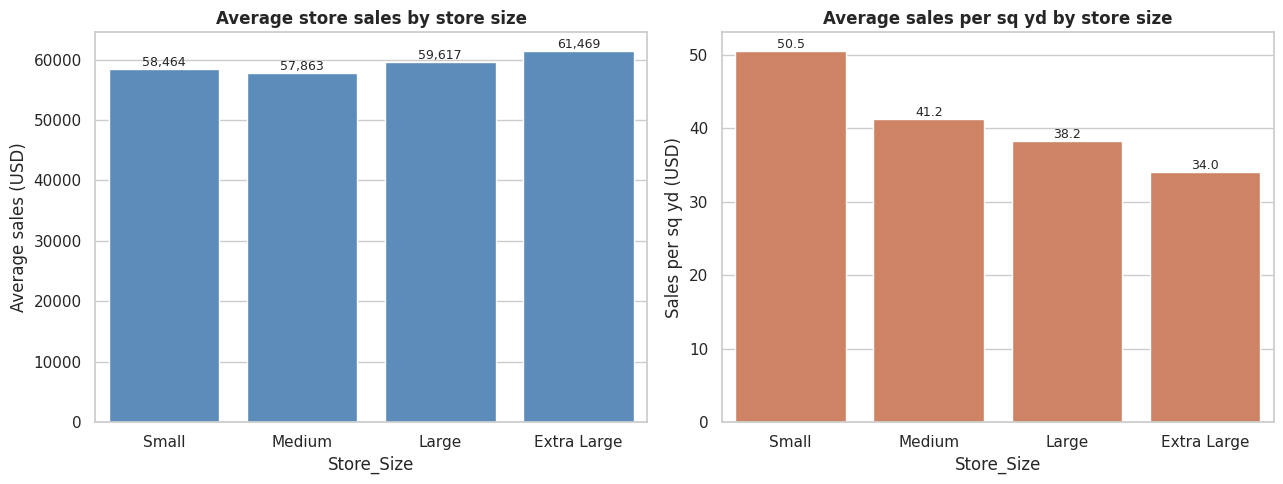

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
order = ["Small", "Medium", "Large", "Extra Large"]
sns.barplot(data=df, x="Store_Size", y="Store_Sales", order=order, errorbar=None, ax=axes[0], color="#4c8cc9")
axes[0].set_title("Average store sales by store size")
axes[0].set_ylabel("Average sales (USD)")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontsize=9)

sns.barplot(data=df, x="Store_Size", y="Sales_per_SqYd", order=order, errorbar=None, ax=axes[1], color="#e07b53")
axes[1].set_title("Average sales per sq yd by store size")
axes[1].set_ylabel("Sales per sq yd (USD)")
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():,.1f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontsize=9)
save_chart("05_size_analysis")

Total sales rise only slightly with size, but **sales per sq yd fall steadily** from small to extra-large stores. Extra space is not turning into proportionally more revenue, so large stores are the least space-efficient.

## 14. Customer Traffic Analysis

In [18]:
df["Traffic_Level"] = pd.qcut(df["Daily_Customer_Count"], 4, labels=["Low", "Moderate", "High", "Peak"])
traffic_summary = df.groupby("Traffic_Level", observed=True).agg(
    Stores=("Store_ID", "count"),
    Avg_Customers=("Daily_Customer_Count", "mean"),
    Avg_Sales=("Store_Sales", "mean"),
    Avg_Sales_per_Customer=("Sales_per_Customer", "mean"),
    Median_Sales_per_Customer=("Sales_per_Customer", "median"),
)
traffic_summary

,Stores,Avg_Customers,Avg_Sales,Avg_Sales_per_Customer,Median_Sales_per_Customer
Traffic_Level,,,,,
Low,227,453.74,"58,448.24",166.56,125.97
Moderate,228,697.02,"59,319.08",85.49,83.44
High,221,874.57,"59,797.56",68.81,67.51
Peak,220,"1,133.50","59,868.23",53.44,52.74


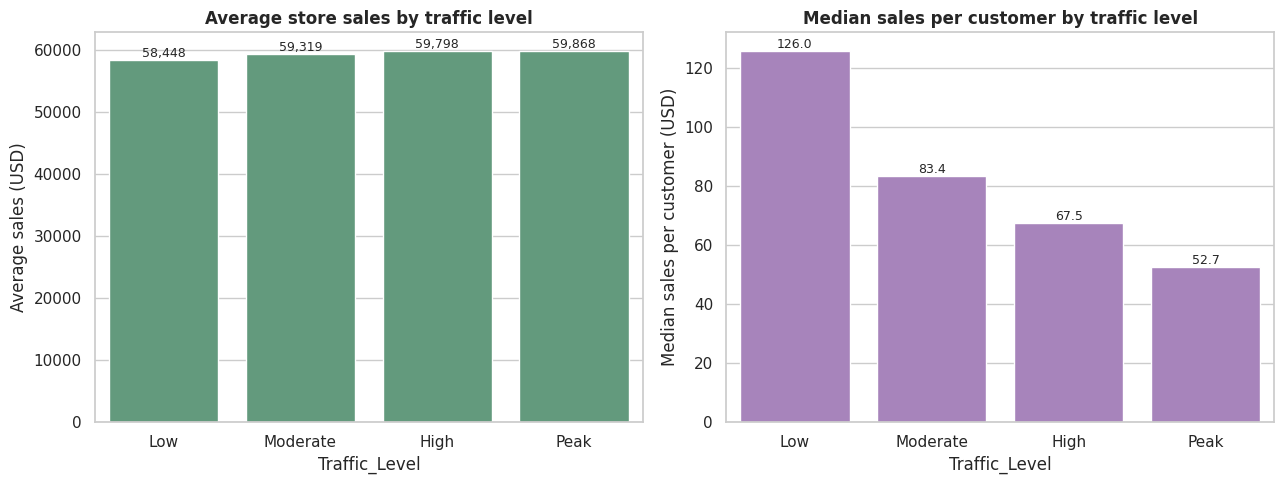

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
t_order = ["Low", "Moderate", "High", "Peak"]
sns.barplot(data=df, x="Traffic_Level", y="Store_Sales", order=t_order, errorbar=None, ax=axes[0], color="#5aa37c")
axes[0].set_title("Average store sales by traffic level")
axes[0].set_ylabel("Average sales (USD)")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontsize=9)

sns.barplot(data=df, x="Traffic_Level", y="Sales_per_Customer", order=t_order, estimator="median",
            errorbar=None, ax=axes[1], color="#a97bc4")
axes[1].set_title("Median sales per customer by traffic level")
axes[1].set_ylabel("Median sales per customer (USD)")
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():,.1f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontsize=9)
save_chart("06_traffic_analysis")

Stores with Low, Moderate, High and Peak footfall all earn about the same total sales (roughly USD 58,000 to 60,000). More customers therefore do not bring more sales. Because total sales stay flat while customer counts rise, sales per customer falls steadily as traffic grows. This is largely arithmetic, not proof of a pattern in customer behaviour, but the main message is clear: footfall alone does not lift store sales, so other factors such as pricing, basket size and location must matter.

## 15. Efficiency Ranking: Best and Worst Stores

In [20]:
cols = ["Store_ID", "Store_Area", "Daily_Customer_Count", "Store_Sales", "Sales_per_SqYd"]
top10 = df.nlargest(10, "Sales_per_SqYd")[cols]
bottom10 = df.nsmallest(10, "Sales_per_SqYd")[cols]
print("Top 10 stores by sales per sq yd")
display(top10.reset_index(drop=True))
print("Bottom 10 stores by sales per sq yd")
display(bottom10.reset_index(drop=True))

Top 10 stores by sales per sq yd


,Store_ID,Store_Area,Daily_Customer_Count,Store_Sales,Sales_per_SqYd
0,557,932,820,89760,96.31
1,469,1060,670,97360,91.85
2,745,854,660,77740,91.03
3,558,1137,700,101780,89.52
4,340,966,900,85470,88.48
5,690,1078,640,94370,87.54
6,407,896,870,75110,83.83
7,811,994,1090,81390,81.88
8,849,919,1560,73810,80.32
9,888,1156,140,92370,79.90


Bottom 10 stores by sales per sq yd


,Store_ID,Store_Area,Daily_Customer_Count,Store_Sales,Sales_per_SqYd
0,853,1477,880,16370,11.08
1,776,1537,660,17670,11.50
2,373,1876,1340,21650,11.54
3,32,1250,990,14920,11.94
4,594,1624,870,20270,12.48
5,253,1583,680,21830,13.79
6,278,1572,1030,21750,13.84
7,726,1445,900,21470,14.86
8,109,1573,650,23740,15.09
9,353,1397,850,21300,15.25


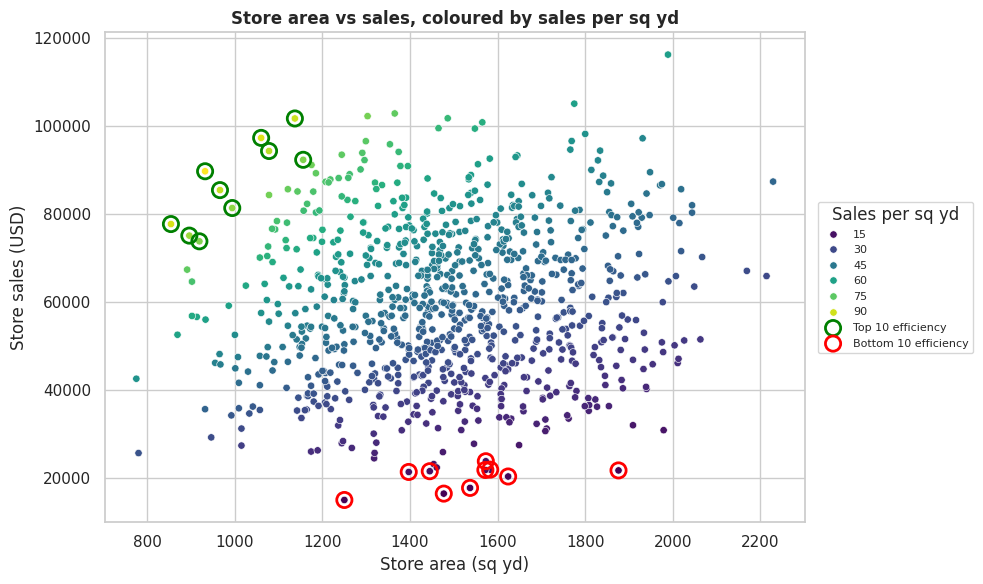

Avg area of top-10 stores   : 999 sq yd
Avg area of bottom-10 stores: 1533 sq yd
Avg area of all stores      : 1485 sq yd


In [21]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df, x="Store_Area", y="Store_Sales", hue="Sales_per_SqYd", palette="viridis", s=28, ax=ax, legend="brief")
ax.scatter(top10["Store_Area"], top10["Store_Sales"], s=120, facecolors="none", edgecolors="green", linewidths=2, label="Top 10 efficiency")
ax.scatter(bottom10["Store_Area"], bottom10["Store_Sales"], s=120, facecolors="none", edgecolors="red", linewidths=2, label="Bottom 10 efficiency")
ax.set_title("Store area vs sales, coloured by sales per sq yd")
ax.set_xlabel("Store area (sq yd)")
ax.set_ylabel("Store sales (USD)")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8, title="Sales per sq yd")
save_chart("07_efficiency_scatter")

print("Avg area of top-10 stores   :", round(top10['Store_Area'].mean()), "sq yd")
print("Avg area of bottom-10 stores:", round(bottom10['Store_Area'].mean()), "sq yd")
print("Avg area of all stores      :", round(df['Store_Area'].mean()), "sq yd")

The most efficient stores are consistently **smaller than average**, while the least efficient are slightly **larger than average** and earn very little for their space. These bottom-10 stores are the first candidates for a performance review, layout redesign or range changes.

## 16. Machine Learning (1): Store Segmentation with K-Means Clustering
K-Means groups stores that look alike on **area, customer traffic and sales**. `Items_Available` is left out because it duplicates `Store_Area`. Features are standardised first, since K-Means is distance based. The number of clusters is chosen with the elbow method and silhouette score.

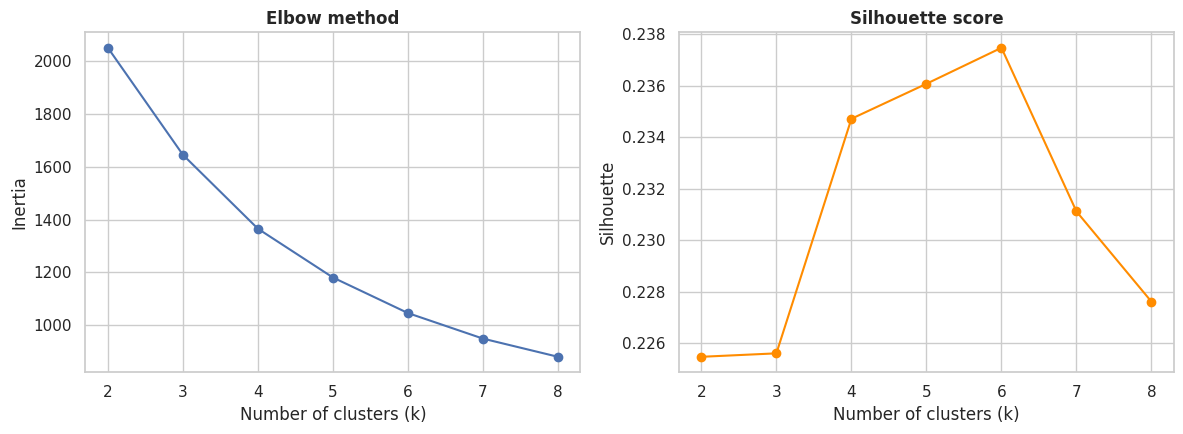

,Inertia,Silhouette
k,,
2,"2,051.04",0.23
3,"1,645.47",0.23
4,"1,365.27",0.23
5,"1,180.41",0.24
6,"1,045.62",0.24
7,948.80,0.23
8,879.89,0.23


In [22]:
seg_features = ["Store_Area", "Daily_Customer_Count", "Store_Sales"]
X_seg = StandardScaler().fit_transform(df[seg_features])

k_values = range(2, 9)
inertia, silhouette = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_seg)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_seg, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(list(k_values), inertia, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), silhouette, marker="o", color="darkorange")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette")
save_chart("08_cluster_selection")

pd.DataFrame({"k": list(k_values), "Inertia": inertia, "Silhouette": silhouette}).set_index("k")

In [23]:
K = 4   # chosen for interpretability; its silhouette score is shown in the table above
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_seg)
df["Cluster"] = kmeans.labels_

profile = df.groupby("Cluster").agg(
    Stores=("Store_ID", "count"),
    Avg_Area=("Store_Area", "mean"),
    Avg_Customers=("Daily_Customer_Count", "mean"),
    Avg_Sales=("Store_Sales", "mean"),
    Avg_Sales_per_SqYd=("Sales_per_SqYd", "mean"),
).sort_values("Avg_Sales")
print(f"Silhouette score for k={K}: {silhouette_score(X_seg, kmeans.labels_):.3f}")
profile

Silhouette score for k=4: 0.235


,Stores,Avg_Area,Avg_Customers,Avg_Sales,Avg_Sales_per_SqYd
Cluster,,,,,
0,254,"1,282.37",844.02,"44,644.37",35.68
1,226,"1,630.44",509.16,"56,588.98",34.97
3,204,"1,699.95","1,019.17","60,446.57",35.88
2,212,"1,367.63",788.73,"78,862.69",58.67


In [24]:
# Name each cluster from its profile (rule-based, so names stay correct if cluster numbers change)
names = {}
names[profile["Avg_Sales"].idxmax()] = "High-Yield Stores"
names[profile["Avg_Sales"].idxmin()] = "Underperforming Stores"
rest = profile.drop(index=list(names))
names[rest["Avg_Customers"].idxmax()] = "Large High-Traffic Stores"
names[rest["Avg_Customers"].idxmin()] = "Large Low-Traffic Stores"

df["Segment"] = df["Cluster"].map(names)
segment_profile = df.groupby("Segment").agg(
    Stores=("Store_ID", "count"),
    Avg_Area=("Store_Area", "mean"),
    Avg_Customers=("Daily_Customer_Count", "mean"),
    Avg_Sales=("Store_Sales", "mean"),
    Avg_Sales_per_SqYd=("Sales_per_SqYd", "mean"),
).sort_values("Avg_Sales", ascending=False)
segment_profile

,Stores,Avg_Area,Avg_Customers,Avg_Sales,Avg_Sales_per_SqYd
Segment,,,,,
High-Yield Stores,212,"1,367.63",788.73,"78,862.69",58.67
Large High-Traffic Stores,204,"1,699.95","1,019.17","60,446.57",35.88
Large Low-Traffic Stores,226,"1,630.44",509.16,"56,588.98",34.97
Underperforming Stores,254,"1,282.37",844.02,"44,644.37",35.68


**Segment meaning**

- **High-Yield Stores:** compact stores with about average traffic but the highest sales. They earn far more per sq yd than any other group and are the model to copy.
- **Large High-Traffic Stores:** big stores with the busiest floors and above-average sales, but low sales per sq yd.
- **Large Low-Traffic Stores:** big stores with the quietest floors. Sales are near average, so footfall is the main gap.
- **Underperforming Stores:** smaller stores with normal traffic but the lowest sales, so each visit is worth little.

The silhouette score (about 0.23) is low. The segments are useful for planning, but their edges are fuzzy and stores form a continuum rather than four sharply separated groups.

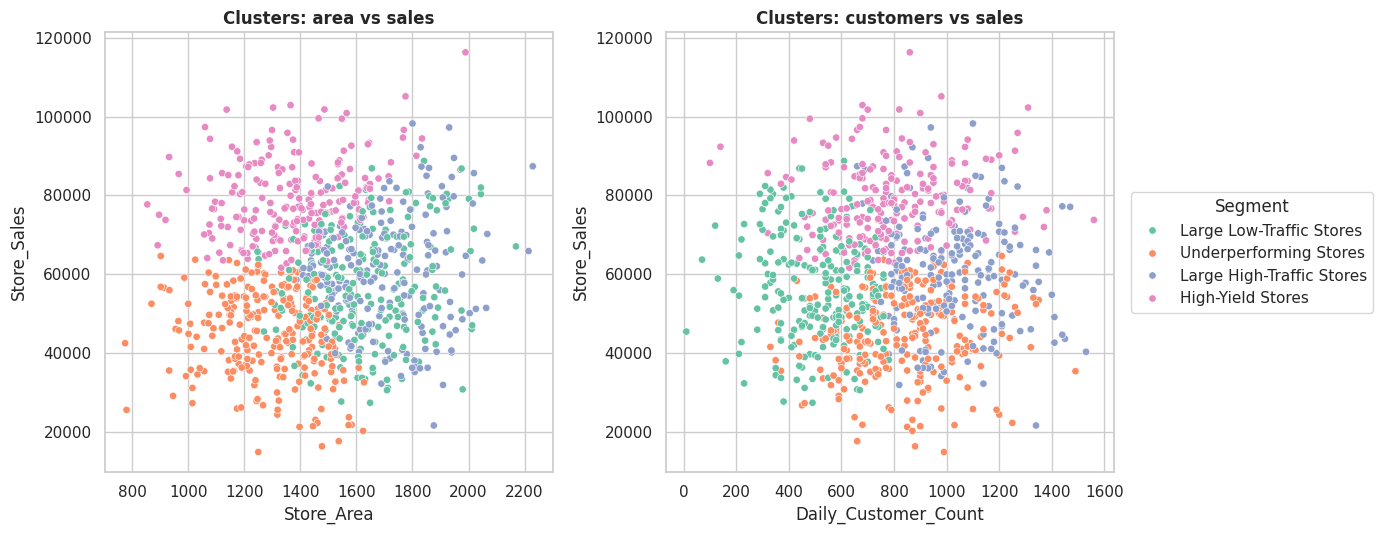

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
palette = sns.color_palette("Set2", K)
sns.scatterplot(data=df, x="Store_Area", y="Store_Sales", hue="Segment", palette=palette, s=28, ax=axes[0])
axes[0].set_title("Clusters: area vs sales")
axes[0].get_legend().remove()
sns.scatterplot(data=df, x="Daily_Customer_Count", y="Store_Sales", hue="Segment", palette=palette, s=28, ax=axes[1])
axes[1].set_title("Clusters: customers vs sales")
sns.move_legend(axes[1], "center left", bbox_to_anchor=(1.02, 0.5), title="Segment")
save_chart("09_clusters")

## 17. Machine Learning (2): Predicting Store Sales
**Goal:** predict `Store_Sales` from `Store_Area` and `Daily_Customer_Count`.

**Design choices**
- `Items_Available` is dropped because it is 99.9% correlated with `Store_Area`.
- The engineered KPIs (`Sales_per_SqYd`, `Sales_per_Customer`) are **not** used as inputs. They are calculated from the target, which would be *data leakage* and give fake accuracy.
- A `DummyRegressor` that always predicts the mean is used as the baseline. A real model must beat it.
- Models are compared with 5-fold cross-validation and a held-out 20% test set, using R-squared, MAE and RMSE.

In [26]:
features = ["Store_Area", "Daily_Customer_Count"]
target = "Store_Sales"
X, y = df[features], df[target]

models = {
    "Baseline (predict mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=10, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, max_depth=2, learning_rate=0.05,
                                                   random_state=RANDOM_STATE),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X, y, cv=cv,
                            scoring=("r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"))
    cv_rows.append({"Model": name,
                    "CV R2 (mean)": scores["test_r2"].mean(),
                    "CV R2 (std)": scores["test_r2"].std(),
                    "CV MAE": -scores["test_neg_mean_absolute_error"].mean(),
                    "CV RMSE": -scores["test_neg_root_mean_squared_error"].mean()})
cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results.round(4)

,CV R2 (mean),CV R2 (std),CV MAE,CV RMSE
Model,,,,
Baseline (predict mean),-0.01,0.01,"14,208.53","17,191.88"
Linear Regression,-0.00,0.02,"14,137.96","17,157.56"
Ridge Regression,-0.00,0.02,"14,137.73","17,156.89"
Random Forest,-0.04,0.02,"14,271.73","17,478.11"
Gradient Boosting,-0.03,0.01,"14,304.99","17,386.56"


In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

test_rows, fitted = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    pred = model.predict(X_test)
    test_rows.append({"Model": name,
                      "Test R2": r2_score(y_test, pred),
                      "Test MAE": mean_absolute_error(y_test, pred),
                      "Test RMSE": np.sqrt(mean_squared_error(y_test, pred))})
test_results = pd.DataFrame(test_rows).set_index("Model")
test_results.round(4)

,Test R2,Test MAE,Test RMSE
Model,,,
Baseline (predict mean),-0.00,"13,292.66","16,518.44"
Linear Regression,0.00,"13,278.37","16,469.18"
Ridge Regression,0.00,"13,277.67","16,468.84"
Random Forest,-0.08,"13,640.21","17,144.53"
Gradient Boosting,-0.02,"13,334.46","16,678.88"


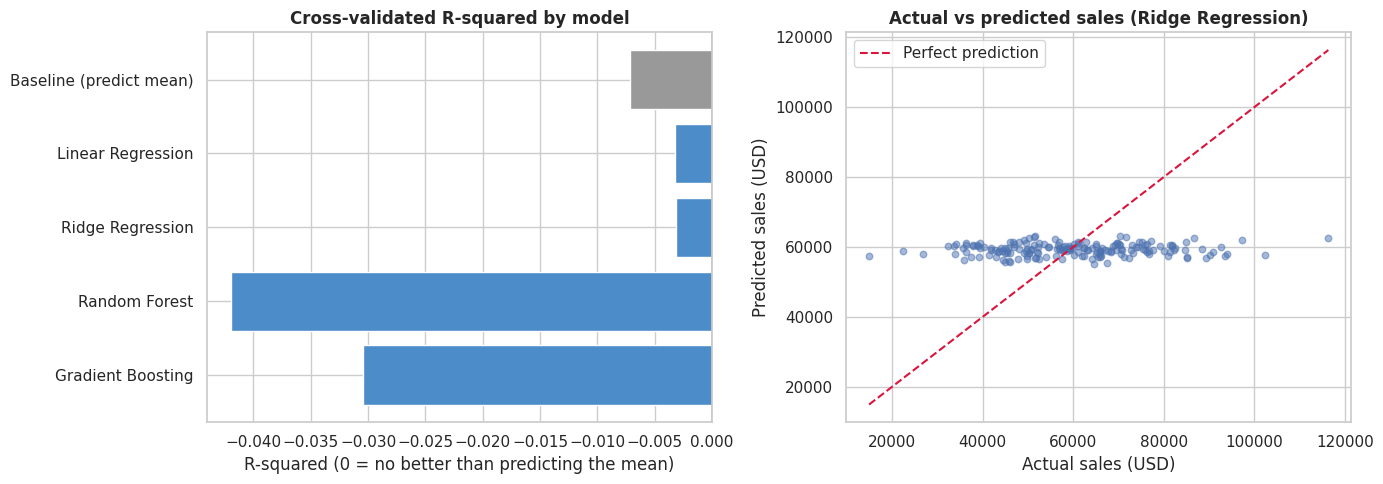

Best model by cross-validated R2: Ridge Regression


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_df = cv_results["CV R2 (mean)"]
colors = ["#999999" if i == 0 else "#4c8cc9" for i in range(len(plot_df))]
axes[0].barh(plot_df.index, plot_df.values, color=colors)
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_title("Cross-validated R-squared by model")
axes[0].set_xlabel("R-squared (0 = no better than predicting the mean)")
axes[0].invert_yaxis()

best_name = cv_results["CV R2 (mean)"].idxmax()
best_pred = fitted[best_name].predict(X_test)
axes[1].scatter(y_test, best_pred, alpha=0.5, s=22)
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
axes[1].plot(lims, lims, color="crimson", linestyle="--", label="Perfect prediction")
axes[1].set_title(f"Actual vs predicted sales ({best_name})")
axes[1].set_xlabel("Actual sales (USD)")
axes[1].set_ylabel("Predicted sales (USD)")
axes[1].legend()
save_chart("10_model_comparison")
print("Best model by cross-validated R2:", best_name)

**Result:** no model meaningfully beats the baseline. Cross-validated R-squared is about 0 for every model (and slightly negative for the tree models, which overfit noise). In plain terms, **store area and customer count cannot predict store sales** in this dataset. This is a valid and useful finding: it shows that sales are driven by factors that are not recorded here, such as location, local income, pricing, product mix, promotions and basket size.

Reporting this honestly is better than forcing a misleadingly high score, for example by feeding in `Sales_per_SqYd`, which would leak the answer.

### 17.1 Robustness Checks
Two quick checks make sure the weak result is real and not caused by a modelling shortcut:
1. Remove the suspicious Store 40 and repeat the model.
2. Add `Items_Available` as a third input.

In [29]:
def cv_r2(frame, cols):
    m = make_pipeline(StandardScaler(), LinearRegression())
    return cross_val_score(m, frame[cols], frame[target], cv=cv, scoring="r2").mean()

checks = pd.Series({
    "Linear model, all stores (area + customers)": cv_r2(df, features),
    "Linear model, Store 40 removed": cv_r2(df[df["Store_ID"] != 40], features),
    "Linear model, + Items_Available": cv_r2(df, features + ["Items_Available"]),
}, name="CV R2")
checks.round(4).to_frame()

,CV R2
"Linear model, all stores (area + customers)",-0.00
"Linear model, Store 40 removed",-0.01
"Linear model, + Items_Available",-0.00


In [30]:
# Which inputs does the best model actually use? (permutation importance on the test set)
perm = permutation_importance(fitted[best_name], X_test, y_test, n_repeats=30,
                              random_state=RANDOM_STATE, scoring="r2")
pd.DataFrame({"Feature": features, "Importance (drop in R2)": perm.importances_mean,
              "Std": perm.importances_std}).set_index("Feature").round(4)

,Importance (drop in R2),Std
Feature,,
Store_Area,0.02,0.02
Daily_Customer_Count,-0.00,0.00


## 18. Summary of Key Findings

In [31]:
best_size = size_summary["Avg_Sales"].idxmax()
eff_by_size = size_summary["Avg_Sales_per_SqYd"]
r_area = df["Store_Area"].corr(df["Store_Sales"])
r_cust = df["Daily_Customer_Count"].corr(df["Store_Sales"])
r_items = df["Store_Area"].corr(df["Items_Available"])

findings = pd.DataFrame({
    "Question": [
        "Stores analysed",
        "Average store sales (USD)",
        "Typical sales range (middle 50%)",
        "Area vs sales correlation",
        "Customer count vs sales correlation",
        "Area vs items correlation",
        "Most space-efficient size group",
        "Least space-efficient size group",
        "Sales per sq yd: Small vs Extra Large",
        "Best model (cross-validated)",
        "Best model CV R-squared",
    ],
    "Finding": [
        f"{len(df)}",
        f"{df['Store_Sales'].mean():,.0f}",
        f"{df['Store_Sales'].quantile(.25):,.0f} to {df['Store_Sales'].quantile(.75):,.0f}",
        f"{r_area:.3f}",
        f"{r_cust:.3f}",
        f"{r_items:.3f}",
        f"{eff_by_size.idxmax()} ({eff_by_size.max():.1f} per sq yd)",
        f"{eff_by_size.idxmin()} ({eff_by_size.min():.1f} per sq yd)",
        f"{eff_by_size['Small']:.1f} vs {eff_by_size['Extra Large']:.1f}",
        best_name,
        f"{cv_results.loc[best_name, 'CV R2 (mean)']:.3f}",
    ],
})
findings.set_index("Question")

,Finding
Question,
Stores analysed,896
Average store sales (USD),"59,351"
Typical sales range (middle 50%),"46,530 to 71,872"
Area vs sales correlation,0.097
Customer count vs sales correlation,0.009
Area vs items correlation,0.999
Most space-efficient size group,Small (50.5 per sq yd)
Least space-efficient size group,Extra Large (34.0 per sq yd)
Sales per sq yd: Small vs Extra Large,50.5 vs 34.0


**Robustness conclusion:** removing Store 40 or adding `Items_Available` leaves R-squared at about zero, so the weak result does not depend on the outlier or on the choice of inputs. Permutation importance is also close to zero for both features.

## 19. Business Decisions and Recommendations

1. **Do not expand floor space to grow sales.** Sales per sq yd fall from about USD 50 in small stores to about USD 34 in extra-large stores while total sales barely rise. New or renovated stores should favour compact, well-stocked layouts.
2. **Study the High-Yield segment.** These stores earn about USD 59 per sq yd versus about USD 35 elsewhere. Compare their pricing, product mix, layout and staffing with other segments and copy what works.
3. **Review the bottom-10 stores by sales per sq yd** (for example Stores 853, 776, 373, 32 and 594). They are mostly larger than average (about 1,530 sq yd) and earn only USD 11 to 15 per sq yd, so they are candidates for layout redesign, range changes or space reduction.
4. **Look beyond footfall.** The busiest stores earn no more in total than the quietest ones, so campaigns that only bring in more customers are unlikely to lift sales. Test basket-building ideas such as bundles, loyalty offers and cross-selling, and track basket value alongside footfall.
5. **Check Store 40's customer count.** Reporting 10 daily customers against USD 45,480 in sales looks like a recording error and should be verified at source.
6. **Collect richer data.** To predict sales, add location type, local population and income, average basket value, number of staff, promotion calendar and opening year.

## 20. Limitations
- The dataset has one row per store and no dates, so seasonality and growth cannot be studied.
- Only four numeric columns are available. Product, price and location information are missing.
- Items_Available duplicates Store_Area, so effectively only two independent inputs exist.
- All findings are associations in one snapshot of the data, not proof of cause and effect.
- The clusters are descriptive. They use sales as an input, so they summarise stores but are not a forecast.

## 21. Conclusion
Store size and footfall explain almost none of the difference in store sales. Larger stores do not sell proportionally more, and busier stores do not earn more in total, so **space efficiency matters more than size or traffic**. Regression models (Linear, Ridge, Random Forest and Gradient Boosting) could not meaningfully beat a simple average baseline, which confirms that the real drivers of sales are missing from this dataset. K-Means segmentation still gives management four clear store types for targeted action, and the efficiency ranking shows exactly which stores to learn from and which to fix.

---
*Prepared by Maanveer Singh | AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026 | BharatCares*